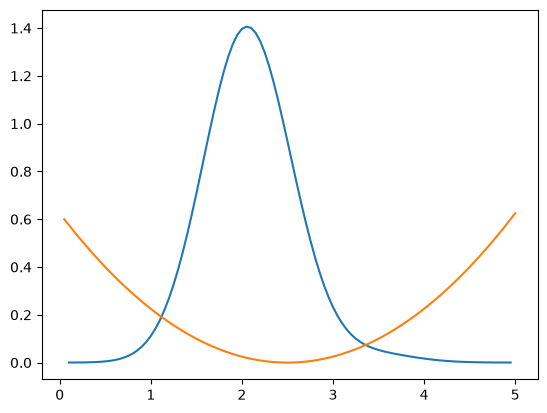

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Parameters
dt = 0.01       # Temporal resolution
dx = 0.05       # Spatial resolution
D = 0.02        # Diffusion constant
t_end = 100     # Final time point

N = 100         # Number of grid points
L = N * dx      # System size

# Time and space vectors
t = np.arange(dt, t_end + dt, dt)
x = np.arange(1, N + 1) * dx

k = 0.1         # Sharpness parameter of the potential

# Initialize concentration fields
rho = np.zeros(N)
rho_0 = np.zeros(N)
rho_temp = np.zeros(N)

# Initial condition
rho_0 = np.exp(-((x - L / 4) / 1)**2)
rho = rho_0.copy()

# External potential and its derivative
U = (k / 2) * (x - L / 2)**2
Up = k * (x - L / 2)

# Periodic boundary condition
Up[0] = Up[-1]

# Store concentration at every time step
rho_T = np.zeros((N, len(t)))

# Time evolution
for i in range(len(t)):

    # Periodic boundary conditions
    rho[-1] = rho[1]
    rho[0] = rho[-2]

    # Product of concentration and potential derivative
    rU = rho * Up

    # Update concentration at interior grid points
    for p in range(1, N - 1):

        rho_temp[p] = rho[p] + dt * (D / dx**2 * (rho[p + 1] + rho[p - 1] - 2 * rho[p]) +
            (rU[p + 1] - rU[p - 1]) / (2 * dx)
        )
    # Update concentration
    rho = rho_temp.copy()

    # Store concentration profile
    rho_T[:, i] = rho

plt.plot(x[1:-1], rho_T[1:-1, 1000], label='Concentration')
plt.plot(x, 2 * U, label='2U (Potential)')
plt.show()